# 空き家対策、どこから支援を始めるか
## Where should vacant-home support start? A prefecture-level priority list

| 項目 | 内容 |
|---|---|
| **作品タイトル** | 空き家対策、どこから支援を始めるか：率・件数・高齢化で優先度をつける |
| **氏名** | 栗田大雅 |
| **依頼元** | 空き家対策の支援策を検討する、国の住宅担当部署（この課題のために私が設定した架空の依頼元です） |
| **読み手** | 同部署の担当課長（データ分析の専門家ではない） |
| **調べたい問い** | 限られた予算で支援を始めるなら、どの都道府県を優先すべきか。空き家の「件数」ではなく「割合」と「高齢化」で見ると、どこが浮かび上がるか。 |

**使用データ：** 授業配布の `japan.csv`（47都道府県）。調査年や「空き家」の定義はCSVからは確認できていないため、「現在の日本」とは言わず「このCSVの値」として扱います。

**先週からの改善点：** ① 割合に加えて件数も見て、対策のタイプを分けました。② 高齢化との関係を散布図で示しました。③ 「優先／注意／件数大」の判定を`for`ループで作り、提案につなげました。④ 結果を組織への提案として書きました。⑤ 茨城県と千葉県を全国と比べるCellを足し、提案にも反映しました。

## 1. データを読み込む / Load the data

グラフの県名は、フォント設定なしで表示できるよう、CSVの英語名の列 `Prefecture` を使います。

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('japan.csv')
print(df.shape)

(47, 92)


## 2. データを確認する / Inspect

分析に使う5列だけを取り出して確認します。`空き家数`と`総住宅数`は戸数、`65歳以上人口`と`総人口`は人数です。

In [15]:
columns = ['Prefecture', '総人口', '65歳以上人口', '総住宅数', '空き家数']
data = df[columns]
data.head()

,Prefecture,総人口,65歳以上人口,総住宅数,空き家数
0,Hokkaido,5140000,1686000,2807200,379800
1,Aomori,1204000,419000,592400,88700
2,Iwate,1181000,408000,579300,93500
3,Miyagi,2280000,659000,1089300,130500
4,Akita,930000,359000,445700,60800


In [16]:
data.info(memory_usage=False)
print()
print('欠損値の合計:', data.isna().sum().sum())
print('空き家数が総住宅数より小さくない県:', (data['空き家数'] >= data['総住宅数']).sum(), '件')

<class 'pandas.DataFrame'>
RangeIndex: 47 entries, 0 to 46
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Prefecture  47 non-null     str  
 1   総人口         47 non-null     int64
 2   65歳以上人口     47 non-null     int64
 3   総住宅数        47 non-null     int64
 4   空き家数        47 non-null     int64
dtypes: int64(4), str(1)
欠損値の合計: 0
空き家数が総住宅数より小さくない県: 0 件


In [17]:
data.describe().round(0)

,総人口,65歳以上人口,総住宅数,空き家数
count,47.0,47.0,47.0,47.0
mean,2658426.0,770957.0,1327821.0,180615.0
std,2793536.0,693147.0,1451568.0,165208.0
min,544000.0,180000.0,256600.0,39900.0
25%,1046500.0,348000.0,511750.0,82700.0
50%,1563000.0,523000.0,813700.0,126800.0
75%,2655000.0,790500.0,1333600.0,197250.0
max,14038000.0,3202000.0,7671600.0,809900.0


47行すべてに値があり、空き家数が総住宅数を超えるような不自然な行もありません。このまま分析に進みます。

## 3. 空き家率・高齢化率と優先度のラベルを作る / Build rates and labels

各県について、空き家率 = 空き家数 ÷ 総住宅数 × 100、高齢化率 = 65歳以上人口 ÷ 総人口 × 100 を計算し、`for`ループで次の4種類に分けます。しきい値は私が決めたもので、変えると結果も変わります。

- **A 優先**：空き家率17%以上 **かつ** 高齢化率32%以上（空き家が多く、今後も増えやすい県）
- **B 注意**：空き家率17%以上だが、高齢化率は32%未満
- **C 件数大**：空き家の件数が全国上位5位（率は高くなくても、戸数が多い）
- **その他**

In [18]:
top5_names = list(df.nlargest(5, '空き家数')['Prefecture'])

rows = []
for index, row in df.iterrows():
    vacancy_rate = row['空き家数'] / row['総住宅数'] * 100
    old_share = row['65歳以上人口'] / row['総人口'] * 100

    if vacancy_rate >= 17 and old_share >= 32:
        tier = 'A 優先'
    elif vacancy_rate >= 17:
        tier = 'B 注意'
    elif row['Prefecture'] in top5_names:
        tier = 'C 件数大'
    else:
        tier = 'その他'

    rows.append({
        'Prefecture': row['Prefecture'],
        '都道府県': row['都道府県'],
        '空き家数': row['空き家数'],
        '空き家率(%)': round(vacancy_rate, 1),
        '高齢化率(%)': round(old_share, 1),
        'tier': tier,
    })

result = pd.DataFrame(rows)
result.head()

,Prefecture,都道府県,空き家数,空き家率(%),高齢化率(%),tier
0,Hokkaido,北海道,379800,13.5,32.8,その他
1,Aomori,青森県,88700,15.0,34.8,その他
2,Iwate,岩手県,93500,16.1,34.5,その他
3,Miyagi,宮城県,130500,12.0,28.9,その他
4,Akita,秋田県,60800,13.6,38.6,その他


## 4. ランキング：空き家率の高い10県 / Ranking by vacancy rate

In [19]:
ranking = result.sort_values('空き家率(%)', ascending=False).head(10)

print('順位  都道府県      空き家率   高齢化率   ラベル')
rank = 1
for index, row in ranking.iterrows():
    print(f"{rank:>2}    {row['都道府県']:<6}  {row['空き家率(%)']:>6.1f}%  {row['高齢化率(%)']:>6.1f}%   {row['tier']}")
    rank += 1

順位  都道府県      空き家率   高齢化率   ラベル
 1    山梨県       21.3%    31.4%   B 注意
 2    和歌山県      20.3%    34.0%   A 優先
 3    長野県       19.6%    32.5%   A 優先
 4    徳島県       19.5%    34.9%   A 優先
 5    高知県       19.1%    36.1%   A 優先
 6    鹿児島県      19.0%    33.5%   A 優先
 7    愛媛県       18.2%    33.9%   A 優先
 8    香川県       18.1%    32.3%   A 優先
 9    山口県       17.6%    35.2%   A 優先
10    栃木県       17.3%    30.0%   B 注意


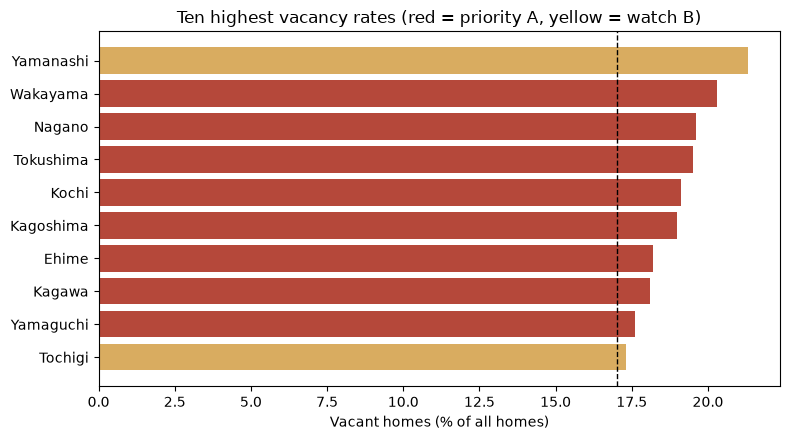

In [20]:
colors = {'A 優先': '#b5483a', 'B 注意': '#d9ac60', 'C 件数大': '#315876', 'その他': '#b8b8b8'}

plt.figure(figsize=(8, 4.5))
plt.barh(ranking['Prefecture'], ranking['空き家率(%)'],
         color=[colors[t] for t in ranking['tier']])
plt.gca().invert_yaxis()
plt.axvline(17, color='black', linestyle='--', linewidth=1)
plt.xlabel('Vacant homes (% of all homes)')
plt.title('Ten highest vacancy rates (red = priority A, yellow = watch B)')
plt.tight_layout()
plt.show()

**読み取り：** 上位10県はすべて空き家率17%以上です（点線）。全国の平均は13.6%（空き家の合計 ÷ 住宅の合計）で、上位の県はそれを大きく上回ります。赤は高齢化率も32%以上の県、黄色は高齢化率が32%未満の県です。

## 5. 高齢化と空き家率の関係 / Ageing and vacancy

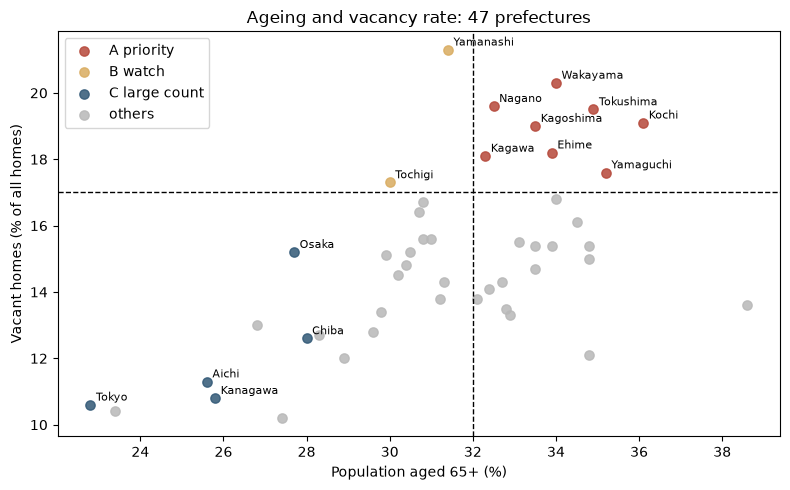

高齢化率と空き家率の相関係数: 0.59


In [21]:
plt.figure(figsize=(8, 5))

for tier, color in colors.items():
    subset = result[result['tier'] == tier]
    plt.scatter(subset['高齢化率(%)'], subset['空き家率(%)'],
                color=color, label=tier.replace('優先', 'priority').replace('注意', 'watch').replace('件数大', 'large count').replace('その他', 'others'),
                alpha=0.85, s=45)

for index, row in result.iterrows():
    if row['tier'] != 'その他':
        plt.annotate(row['Prefecture'], (row['高齢化率(%)'], row['空き家率(%)']),
                     fontsize=8, xytext=(4, 3), textcoords='offset points')

plt.axhline(17, color='black', linestyle='--', linewidth=1)
plt.axvline(32, color='black', linestyle='--', linewidth=1)
plt.xlabel('Population aged 65+ (%)')
plt.ylabel('Vacant homes (% of all homes)')
plt.title('Ageing and vacancy rate: 47 prefectures')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

print('高齢化率と空き家率の相関係数:', round(result['高齢化率(%)'].corr(result['空き家率(%)']), 2))

**読み取り：** 高齢化率が高い県ほど空き家率も高い傾向があります（相関係数 約0.59）。右上の区画（点線の外側）が優先Aの県です。山梨県と栃木県は空き家率は高いのに高齢化率が低めなので、右上には入らず「注意B」になりました。相関があっても、高齢化が空き家の原因とは言えません。

## 6. 件数と割合は違う / Counts versus shares

空き家の件数が最も多い5都府県で、件数と空き家率を並べます。

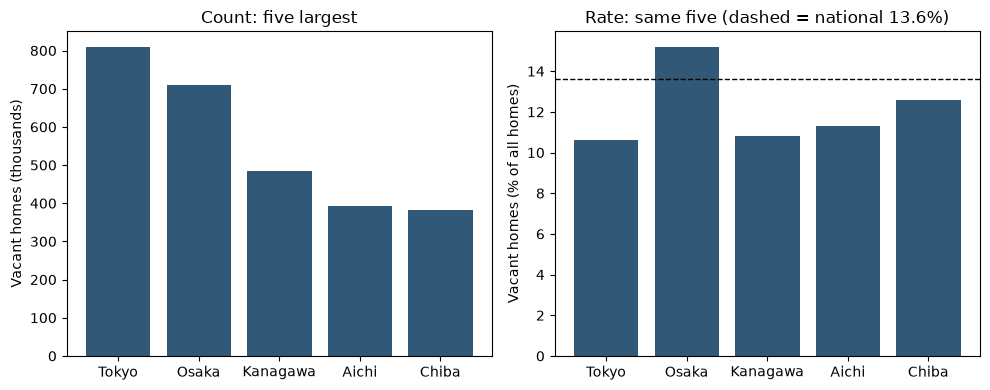

上位5都府県の空き家合計: 2,780,300戸（全国の32.8%）


In [22]:
top5_rows = result.sort_values('空き家数', ascending=False).head(5)
national = df['空き家数'].sum() / df['総住宅数'].sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(top5_rows['Prefecture'], top5_rows['空き家数'] / 1000, color='#315876')
axes[0].set_ylabel('Vacant homes (thousands)')
axes[0].set_title('Count: five largest')

axes[1].bar(top5_rows['Prefecture'], top5_rows['空き家率(%)'], color='#315876')
axes[1].axhline(national, color='black', linestyle='--', linewidth=1)
axes[1].set_ylabel('Vacant homes (% of all homes)')
axes[1].set_title(f'Rate: same five (dashed = national {national:.1f}%)')

plt.tight_layout()
plt.show()

total_vacant = df['空き家数'].sum()
five_total = 0
for index, row in top5_rows.iterrows():
    five_total += row['空き家数']
print(f"上位5都府県の空き家合計: {five_total:,}戸（全国の{five_total / total_vacant * 100:.1f}%）")

**読み取り：** 東京都は約81万戸で件数は最多ですが、空き家率は10.6%と全国平均より低いです。上位5都府県で全国の空き家の33%を占めるため、「戸数」では都市部が重要ですが、「割合」の問題とは別の話です。

## 7. 優先度ごとのまとめ / Summary by tier

`for`ループで、ラベルごとに県数・空き家の合計・全国に占める割合を集計します。

In [23]:
total_vacant = result['空き家数'].sum()
summary = []

for tier in ['A 優先', 'B 注意', 'C 件数大', 'その他']:
    count = 0
    vacant = 0
    names = []
    for index, row in result.iterrows():
        if row['tier'] == tier:
            count += 1
            vacant += row['空き家数']
            names.append(row['都道府県'])
    summary.append({
        'ラベル': tier,
        '県数': count,
        '空き家合計(戸)': vacant,
        '全国比(%)': round(vacant / total_vacant * 100, 1),
        '県': '、'.join(names) if tier != 'その他' else '（省略）',
    })

pd.DataFrame(summary)

,ラベル,県数,空き家合計(戸),全国比(%),県
0,A 優先,8,956200,11.3,長野県、和歌山県、山口県、徳島県、香川県、愛媛県、高知県、鹿児島県
1,B 注意,2,250700,3.0,栃木県、山梨県
2,C 件数大,5,2780300,32.8,千葉県、東京都、神奈川県、愛知県、大阪府
3,その他,32,4501700,53.0,（省略）


## 8. 確認：元の行と比べる / Sanity check

In [24]:
row = df[df['Prefecture'] == 'Nagano'].iloc[0]
print('長野県の元データ:', row['空き家数'], '/', row['総住宅数'], '戸、', row['65歳以上人口'], '/', row['総人口'], '人')
print(f"手計算: 空き家率 {row['空き家数'] / row['総住宅数'] * 100:.1f}%、高齢化率 {row['65歳以上人口'] / row['総人口'] * 100:.1f}%")
print(result[result['Prefecture'] == 'Nagano'][['空き家率(%)', '高齢化率(%)', 'tier']].to_string(index=False))

長野県の元データ: 197300 / 1007900 戸、 657000 / 2020000 人
手計算: 空き家率 19.6%、高齢化率 32.5%
 空き家率(%)  高齢化率(%) tier
    19.6     32.5 A 優先


## 9. 茨城県・千葉県と比べる / Compare Ibaraki and Chiba

全国の結果を、茨城県と千葉県に当てはめて見ます。茨城県は私が住んでいる県、千葉県は通っている大学がある県なので、身近な2県として選びました。各県の空き家率・高齢化率・空き家の件数が47都道府県の何位か、全国の平均と比べてどうかを、`for`ループで出します。順位は「高い順」で、1位が最も高い県です。

In [25]:
targets = ['Ibaraki', 'Chiba']

# 全国の値（県ごとの平均ではなく、全部を合計して計算）
national_vacancy = df['空き家数'].sum() / df['総住宅数'].sum() * 100
national_old = df['65歳以上人口'].sum() / df['総人口'].sum() * 100
national_detached = df['一戸建住宅数'].sum() / df['総住宅数'].sum() * 100

# 高い順の並び（先頭が1位）
by_rate = result.sort_values('空き家率(%)', ascending=False)['Prefecture'].tolist()
by_old = result.sort_values('高齢化率(%)', ascending=False)['Prefecture'].tolist()
by_count = result.sort_values('空き家数', ascending=False)['Prefecture'].tolist()

print(f"全国: 空き家率 {national_vacancy:.1f}% / 高齢化率 {national_old:.1f}% / 一戸建比率 {national_detached:.1f}%")
print()

compare = []
for name in targets:
    row = df[df['Prefecture'] == name].iloc[0]
    res = result[result['Prefecture'] == name].iloc[0]
    detached = row['一戸建住宅数'] / row['総住宅数'] * 100
    compare.append({
        '県': row['都道府県'],
        '空き家数(戸)': row['空き家数'],
        '件数の順位': by_count.index(name) + 1,
        '空き家率(%)': res['空き家率(%)'],
        '空き家率の順位': by_rate.index(name) + 1,
        '高齢化率(%)': res['高齢化率(%)'],
        '高齢化率の順位': by_old.index(name) + 1,
        '一戸建比率(%)': round(detached, 1),
        'ラベル': res['tier'],
    })

pd.DataFrame(compare)

全国: 空き家率 13.6% / 高齢化率 29.0% / 一戸建比率 46.1%



,県,空き家数(戸),件数の順位,空き家率(%),空き家率の順位,高齢化率(%),高齢化率の順位,一戸建比率(%),ラベル
0,茨城県,197200,13,14.8,25,30.4,32,61.3,その他
1,千葉県,382500,5,12.6,40,28.0,40,46.2,C 件数大


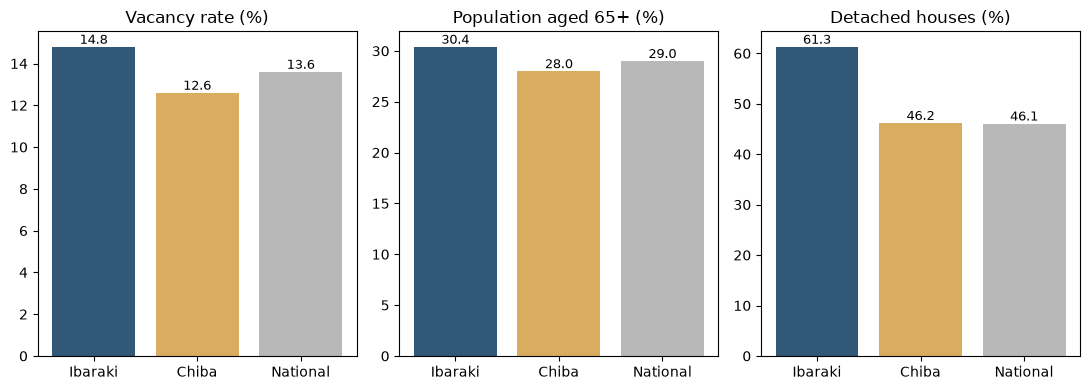

In [26]:
labels = ['Ibaraki', 'Chiba', 'National']
bar_colors = ['#315876', '#d9ac60', '#b8b8b8']

values = {
    'Vacancy rate (%)': [compare[0]['空き家率(%)'], compare[1]['空き家率(%)'], national_vacancy],
    'Population aged 65+ (%)': [compare[0]['高齢化率(%)'], compare[1]['高齢化率(%)'], national_old],
    'Detached houses (%)': [compare[0]['一戸建比率(%)'], compare[1]['一戸建比率(%)'], national_detached],
}

fig, axes = plt.subplots(1, 3, figsize=(11, 4))

position = 0
for title, nums in values.items():
    axes[position].bar(labels, nums, color=bar_colors)
    axes[position].set_title(title)
    for i in range(len(nums)):
        axes[position].text(i, nums[i], f'{nums[i]:.1f}', ha='center', va='bottom', fontsize=9)
    position += 1

plt.tight_layout()
plt.show()

**読み取り**
- 茨城県の空き家率は14.8%で、全国（13.6%）より少し高く、47都道府県中25位です。高齢化率は30.4%で32位なので、高齢化の順位よりも空き家率の順位のほうが高めです。ラベルは「その他」で、優先Aにも注意Bにも入りませんでした。
- 千葉県は空き家が38万戸で、件数は全国5位です。でも空き家率は12.6%で40位と、全国より低いです。ラベルは「件数大」です。
- 一戸建比率は茨城県が61.3%（全国9位）、千葉県が46.2%、全国が46.1%で、茨城県だけ高いです。全国で見ると一戸建比率と空き家率の相関は約0.41ありますが、2県を比べただけでは関係があるとは言えません。

**住んでいる茨城県で見たこと（データではなく、私の観察）：** 私の身近では、地震の影響や買取をきっかけに、空き家が解体されたり、新しい住宅が建てられたりするのをよく見るようになりました。ただし、このCSVは1時点の数字だけなので、空き家が減っているのか、建て替えが増えているのかは確かめられません。気づきとして書いておきます。

## わかったこと / Findings

- **優先Aは8県：** 長野県、和歌山県、山口県、徳島県、香川県、愛媛県、高知県、鹿児島県。空き家率17%以上かつ高齢化率32%以上で、空き家の合計は約95.6万戸、全国の11%です。8県の平均は空き家率 18.9%、高齢化率 34.1%でした。
- **注意Bは2県：** 栃木県、山梨県。空き家率は高い（山梨県は21.3%で全国最高）ものの、高齢化率は32%未満です。
- **件数と割合は別の問題：** 空き家の件数の上位5都府県（東京都・大阪府・神奈川県・愛知県・千葉県）は全国の33%を占めますが、空き家率はすべて17%未満です。
- **茨城県と千葉県：** 茨城県は空き家率14.8%で全国平均より少し高く、25位。千葉県は件数は5位だが、空き家率は12.6%で40位と低い。2県とも優先Aには入らなかった。
- **高齢化との関係：** 高齢化率が高いほど空き家率も高い傾向があります（相関 約0.59）。ただし原因とは言えません。

## 組織への提案 / Recommendations

1. **第1次の重点支援は優先Aの8県から。** 空き家の割合が高く、高齢化も進んでいるため、今後も増えやすい可能性があります。
2. **山梨県と栃木県は注意枠として、実態を調べる。** 割合は高いのに高齢化率は低めなので、別の理由（別荘、人口移動など）がないか確認する価値があります。
3. **東京都・大阪府・千葉県などは、割合ではなく戸数に合わせた別の施策にする。** 割合は低くても戸数は多く、対策の種類が優先Aの県とは違うと考えられます。
4. **茨城県は優先Aではないが、様子を見る。** 空き家率が全国平均より少し高く、一戸建比率も61.3%（全国9位）と高いので、今後の変化を見ておく価値があります。

## 限界 / Limitations

- 優先度のしきい値（17%・32%・上位5位）は私が決めたものです。変えると結果も変わります。
- CSVには調査年と「空き家」の定義がありません。別荘や賃貸の空室を含む場合、解釈が変わります。
- 都道府県の集計値なので、同じ県の中の地域差（市町村ごとの違い）は見えません。
- 茨城県で見た解体や建て替えの様子は私の観察で、このデータでは確かめていません。時間による変化を見るには、複数年のデータが必要です。